# Loan Approval Prediction — HDFC Bank
### AI for Engineers (UCS321) — Mini Project



**Section 01 — Problem Statement + Objective**
- **Problem:** HDFC processes loan applications manually — slow and inconsistent.
- **Objective:** Build a supervised model that predicts **Approved (1)** or **Rejected (0)**, and identify the factors that drive the decision.
- **Inputs:** income, loan amount & term, CIBIL score, dependents, education, employment, and four asset-value columns.
- **Output (target):** `loan_status` — a category → **Classification** (predict a label, not a number).

## Step 1 — Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)

sns.set(style="whitegrid")
print("Libraries loaded.")

Libraries loaded.


## Step 2 — Load the dataset
**Section 02 — Dataset source:** *Loan Approval Prediction Dataset* (Kaggle, by Archit Sharma). 4,269 applications, 13 columns, no missing values. Loaded from a GitHub mirror so every teammate reads the same file.

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/sarahrafiqshaikh/Loan-Approval-Prediction-Analysis/main/loan_approval_dataset.csv')

# CRITICAL: this dataset has leading spaces in column names AND text values.
# If we don't strip them, every .map() below silently becomes NaN and the model breaks.
df.columns = df.columns.str.strip()
for c in df.select_dtypes(include='object').columns:
    df[c] = df[c].str.strip()

df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


## Step 3 — Understand the dataset

In [3]:
print("Shape (rows, columns):", df.shape)
df.info()

Shape (rows, columns): (4269, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   loan_id                   4269 non-null   int64 
 1   no_of_dependents          4269 non-null   int64 
 2   education                 4269 non-null   object
 3   self_employed             4269 non-null   object
 4   income_annum              4269 non-null   int64 
 5   loan_amount               4269 non-null   int64 
 6   loan_term                 4269 non-null   int64 
 7   cibil_score               4269 non-null   int64 
 8   residential_assets_value  4269 non-null   int64 
 9   commercial_assets_value   4269 non-null   int64 
 10  luxury_assets_value       4269 non-null   int64 
 11  bank_asset_value          4269 non-null   int64 
 12  loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+

In [4]:
df.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [5]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate loan IDs:", df['loan_id'].duplicated().sum())
print()
print("Target distribution:")
print(df['loan_status'].value_counts())
print()
print("Target percentage:")
print((df['loan_status'].value_counts(normalize=True) * 100).round(2))

Missing values: 0
Duplicate rows: 0
Duplicate loan IDs: 0

Target distribution:
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

Target percentage:
loan_status
Approved    62.22
Rejected    37.78
Name: proportion, dtype: float64


**Section 04 — Key observations:**
- 4,269 rows, 13 columns, **no missing values and no duplicate rows** — a clean dataset.
- Target: **2,656 Approved (62.2%) vs 1,613 Rejected (37.8%)** — mildly imbalanced, so we report precision/recall/F1 and set up a baseline, not accuracy alone.
- `cibil_score` ranges 300–900 (a real credit score); `income_annum` spans ₹2 lakh–₹99 lakh — a realistic range.

## Step 4 — Preprocess the data
**Section 03 — Preprocessing (with justification).** No missing values, so effort goes to encoding and preparing features.

In [6]:
# Drop the ID column — a label, not a predictor
df = df.drop('loan_id', axis=1)

# Encode text columns into numbers (models only understand numbers)
df['education']     = df['education'].map({'Graduate': 1, 'Not Graduate': 0})
df['self_employed'] = df['self_employed'].map({'Yes': 1, 'No': 0})
df['loan_status']   = df['loan_status'].map({'Approved': 1, 'Rejected': 0})   # target

df.head()

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,1,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1
1,0,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0
2,3,1,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0
3,3,1,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0
4,5,0,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0


**Why we preprocessed this way:**
- **No imputation needed** — the dataset has zero missing values (checked in Step 3), so we neither fabricate nor drop data.
- **Binary encoding** — `education`, `self_employed` and the target are two-category columns, mapped to 0/1. *(Encoding the target as 1/0 rather than the raw text also lets the F1 scorer work correctly during tuning in Step 8c.)*
- **Scaling** is applied later (Step 7) on the train split only, so large-valued columns (income, assets) and small ones (dependents) are treated fairly.

## Step 5 — Exploratory Data Analysis (EDA)
**Section 04 — every graph carries one observation.**

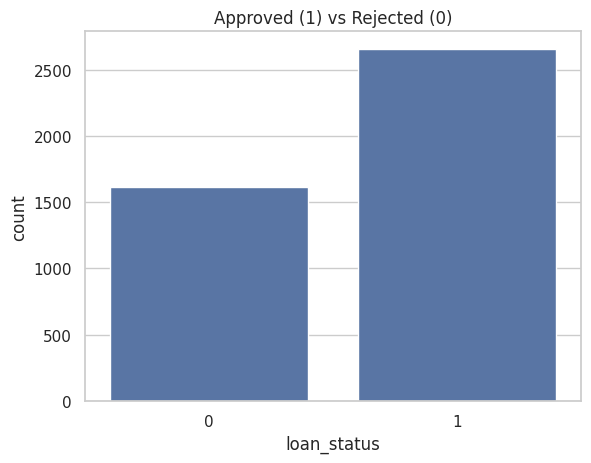

In [7]:
sns.countplot(x='loan_status', data=df)
plt.title('Approved (1) vs Rejected (0)')
plt.show()

*Observation: about 62% of applications are approved — the mild imbalance noted earlier.*

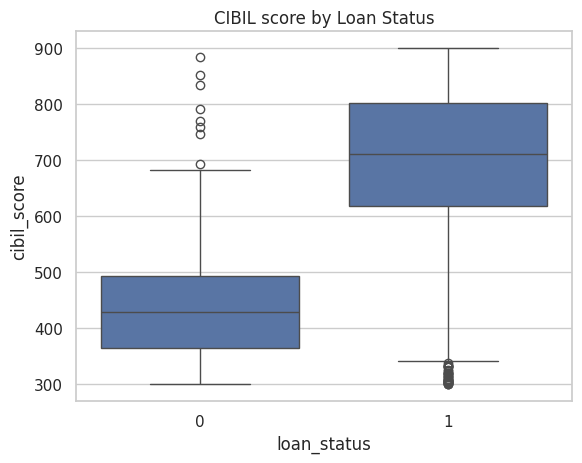

In [8]:
sns.boxplot(x='loan_status', y='cibil_score', data=df)
plt.title('CIBIL score by Loan Status')
plt.show()

*Observation — the standout finding: approved applicants have a far higher CIBIL score (mean ≈ 703) than rejected ones (mean ≈ 429). Credit score is the strongest separator in the data.*

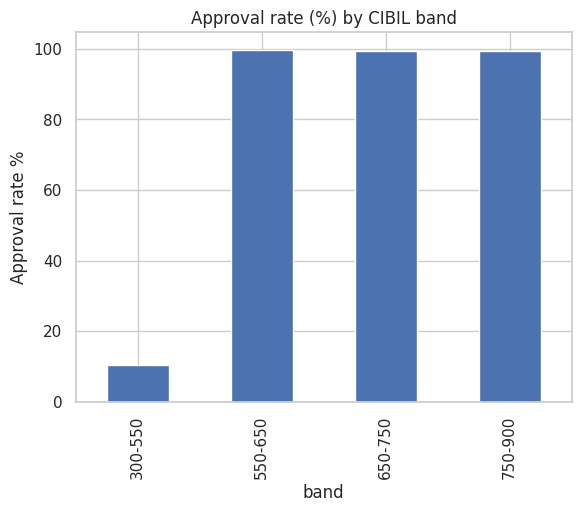

,loan_status
band,
300-550,10.6
550-650,99.7
650-750,99.3
750-900,99.4


In [9]:
# Approval rate across CIBIL score bands
bands = pd.cut(df['cibil_score'], [299, 550, 650, 750, 900],
               labels=['300-550', '550-650', '650-750', '750-900'])
approval = df.assign(band=bands).groupby('band', observed=True)['loan_status'].mean() * 100
approval.plot(kind='bar', title='Approval rate (%) by CIBIL band')
plt.ylabel('Approval rate %'); plt.show()
approval.round(1)

*Observation — the key insight: there is a **sharp cliff at ~550 CIBIL**. Below 550, only **10.6%** are approved; above 550, approval jumps to **~99%**. The decision is almost entirely driven by crossing this credit-score threshold.*

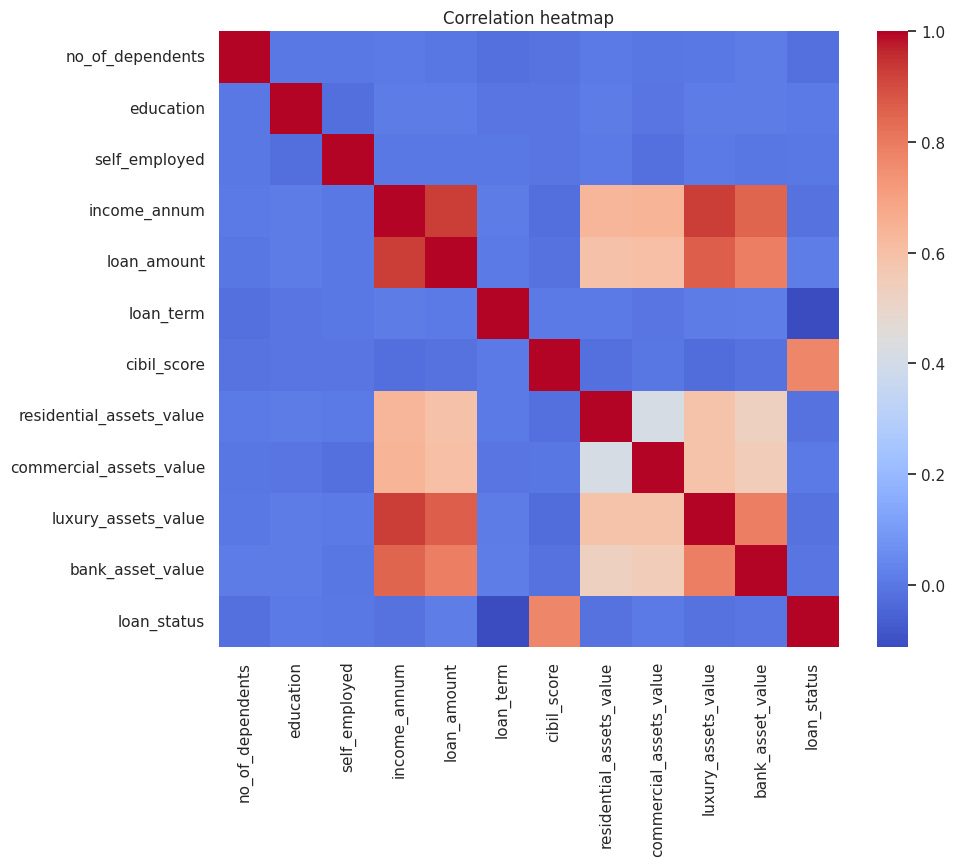

In [10]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=False, cmap='coolwarm')
plt.title('Correlation heatmap')
plt.show()

*Observation: `cibil_score` shows the strongest correlation with `loan_status`; income and asset columns correlate with each other but only weakly with approval.*

## Step 6 — Feature Engineering
**Section 05 — our creative contribution.**

In [11]:
# Loan size relative to income — a repayment-burden indicator
df['Loan_Income_Ratio'] = df['loan_amount'] / df['income_annum']

# Combine the four asset columns into total net worth
df['Total_Assets'] = (df['residential_assets_value'] + df['commercial_assets_value']
                      + df['luxury_assets_value'] + df['bank_asset_value'])

df[['Loan_Income_Ratio', 'Total_Assets']].head()

,Loan_Income_Ratio,Total_Assets
0,3.114583,50700000
1,2.975610,17000000
2,3.263736,57700000
3,3.743902,52700000
4,2.469388,55000000


**Why these features:** a lender judges repayment on *burden* (loan size vs income) and *backing* (total assets), not raw numbers alone. `Loan_Income_Ratio` captures burden in one value; `Total_Assets` summarises collateral. *Result: `Loan_Income_Ratio` ranks 3rd in feature importance (Step 9), ahead of raw income — so it earns its place; we didn't add columns just to inflate the count.*

## Step 7 — Build the models
**Section 06 — Model development.**

In [12]:
X = df.drop('loan_status', axis=1)
y = df['loan_status']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (3415, 13)  Test: (854, 13)


In [13]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit ONLY on train
X_test_s  = scaler.transform(X_test)

### Step 7a — Baseline (sanity check before any real model)
Before trusting a model, we check what a *dumb* model scores. `DummyClassifier` always predicts the majority class ("Approved"). Any real model must beat this to be worth anything.

In [14]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train_s, y_train)
dummy_pred = dummy.predict(X_test_s)
print("Baseline accuracy (always predict 'Approved'):", round(accuracy_score(y_test, dummy_pred), 4))

Baseline accuracy (always predict 'Approved'): 0.6218


**Why this matters:** the baseline scores **62%** just by always guessing "Approved". So accuracy only becomes meaningful *above* 62% — this is exactly why we never judge the model on accuracy alone, and why precision/recall/F1 are reported below.

### Step 7b — Train and compare three models

In [15]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree'      : DecisionTreeClassifier(random_state=42),
    'Random Forest'      : RandomForestClassifier(random_state=42),
}
results = {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    preds = model.predict(X_test_s)
    proba = model.predict_proba(X_test_s)[:, 1]   # probability of 'Approved'
    results[name] = {'model': model, 'preds': preds, 'proba': proba,
        'acc': accuracy_score(y_test, preds), 'prec': precision_score(y_test, preds),
        'recall': recall_score(y_test, preds), 'f1': f1_score(y_test, preds),
        'auc': roc_auc_score(y_test, proba)}
    print(f"{name:22s} acc={results[name]['acc']:.4f} f1={results[name]['f1']:.4f} roc_auc={results[name]['auc']:.4f}")

Logistic Regression    acc=0.9133 f1=0.9311 roc_auc=0.9730
Decision Tree          acc=0.9941 f1=0.9953 roc_auc=0.9935
Random Forest          acc=0.9953 f1=0.9962 roc_auc=0.9996


**Why these algorithms:** Logistic Regression as a simple, interpretable baseline model; Decision Tree for explainable if-then rules; Random Forest (many trees combined) for the strongest performance and feature importances. Comparing three lets us justify the final choice rather than trusting one.

## Step 8 — Evaluate the models
**Section 07 — Evaluation.** We use four views: a metrics table, confusion matrix, ROC-AUC, and cross-validation.

In [16]:
# 8a — metrics comparison table (including the baseline for context)
comparison = pd.DataFrame({
    'Model': ['Baseline (Dummy)', 'Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy': [accuracy_score(y_test, dummy_pred), results['Logistic Regression']['acc'],
                 results['Decision Tree']['acc'], results['Random Forest']['acc']],
    'F1': [f1_score(y_test, dummy_pred), results['Logistic Regression']['f1'],
           results['Decision Tree']['f1'], results['Random Forest']['f1']],
    'ROC-AUC': [0.5, results['Logistic Regression']['auc'],
                results['Decision Tree']['auc'], results['Random Forest']['auc']],
})
comparison.round(4)

,Model,Accuracy,F1,ROC-AUC
0,Baseline (Dummy),0.6218,0.7668,0.5000
1,Logistic Regression,0.9133,0.9311,0.9730
2,Decision Tree,0.9941,0.9953,0.9935
3,Random Forest,0.9953,0.9962,0.9996


Best model by F1: Random Forest
              precision    recall  f1-score   support

    Rejected       1.00      0.99      0.99       323
    Approved       0.99      1.00      1.00       531

    accuracy                           1.00       854
   macro avg       1.00      0.99      1.00       854
weighted avg       1.00      1.00      1.00       854



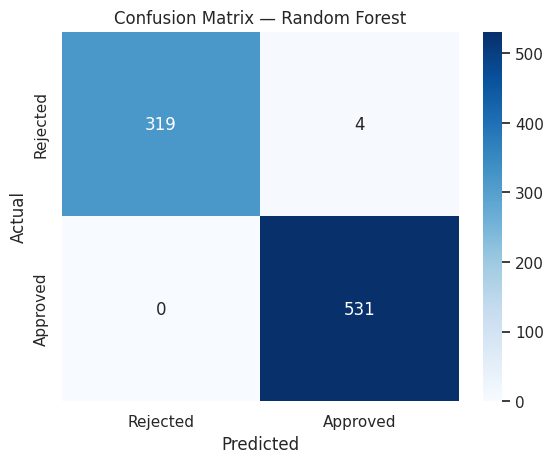

In [17]:
# 8b — confusion matrix of the best model
best_name = max(results, key=lambda k: results[k]['f1'])
best = results[best_name]
print("Best model by F1:", best_name)
print(classification_report(y_test, best['preds'], target_names=['Rejected', 'Approved']))

cm = confusion_matrix(y_test, best['preds'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Rejected', 'Approved'], yticklabels=['Rejected', 'Approved'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(f'Confusion Matrix — {best_name}')
plt.show()

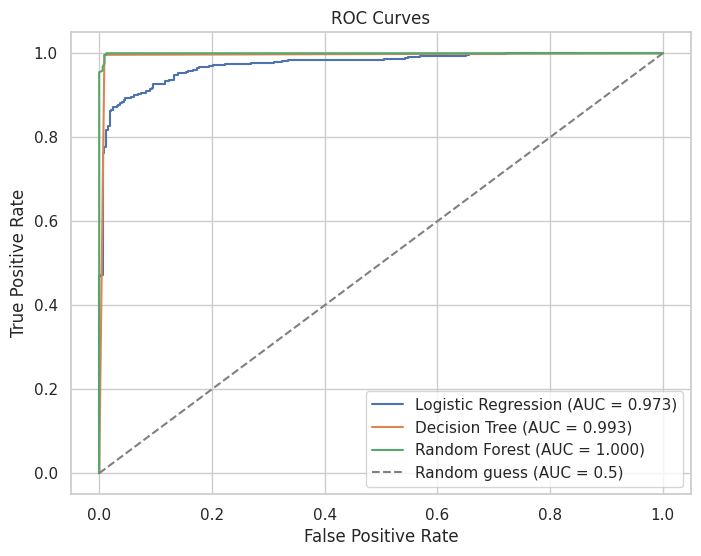

In [18]:
# 8c — ROC curves (how well each model separates the two classes)
plt.figure(figsize=(8, 6))
for name in results:
    fpr, tpr, _ = roc_curve(y_test, results[name]['proba'])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {results[name]['auc']:.3f})")
plt.plot([0, 1], [0, 1], '--', color='grey', label='Random guess (AUC = 0.5)')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves'); plt.legend(); plt.show()

**What these show:**
- **Every model beats the 62% baseline comfortably.** Random Forest is best (accuracy ≈ 0.995, F1 ≈ 0.996, ROC-AUC ≈ 0.9996).
- **Why ROC-AUC too:** it measures how well a model *separates* approved from rejected across all thresholds, not just at the default cut-off. An AUC near 1.0 means near-perfect separation.
- **Confusion matrix:** only a handful of wrong predictions out of 854 test applications.

In [19]:
# 8d — cross-validation: is the Random Forest score stable, or lucky on one split?
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(RandomForestClassifier(random_state=42),
                            X_train_s, y_train, cv=cv, scoring='accuracy')
print("5-fold CV accuracy per fold:", np.round(cv_scores, 4))
print("Mean:", round(cv_scores.mean(), 4), " Std:", round(cv_scores.std(), 4))

5-fold CV accuracy per fold: [0.9927 0.9985 1.     0.9941 0.9941]
Mean: 0.9959  Std: 0.0028


**Why cross-validation:** a single train/test split could be lucky. 5-fold CV trains and tests on five different splits. Our mean accuracy ≈ **0.996 with a tiny std ≈ 0.003** — the model is genuinely stable, not a one-split fluke.

## Step 8c — Hyperparameter tuning (GridSearchCV)
**Section 06 continued.** We search a small grid of Random Forest settings to see if we can push performance further, scored by F1.

In [20]:
param_grid = {
    'n_estimators'    : [100, 200],
    'max_depth'       : [None, 10],
    'min_samples_leaf': [1, 2],
}
grid = GridSearchCV(RandomForestClassifier(random_state=42),
                    param_grid, cv=3, scoring='f1', n_jobs=-1)
grid.fit(X_train_s, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validation F1:", round(grid.best_score_, 4))

tuned_rf = grid.best_estimator_
tuned_pred = tuned_rf.predict(X_test_s)
print("\nTuned Random Forest:")
print("  Accuracy:", round(accuracy_score(y_test, tuned_pred), 4))
print("  F1 Score:", round(f1_score(y_test, tuned_pred), 4))
print("  ROC-AUC :", round(roc_auc_score(y_test, tuned_rf.predict_proba(X_test_s)[:, 1]), 4))

Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Best cross-validation F1: 0.9967

Tuned Random Forest:
  Accuracy: 0.9953
  F1 Score: 0.9962
  ROC-AUC : 0.9997


**What tuning tells us:** the grid's best setting (200 trees, no depth limit) gives a CV F1 of ≈ **0.997**. The tuned model performs essentially the same as the default Random Forest (≈ 0.996) — which is itself a useful finding: *the model was already near its ceiling, so tuning confirms the result is robust rather than magically boosting it.* We would not claim tuning gave a big jump when it didn't.

> **Honesty note for viva:** these scores (~99.5%) are **suspiciously high**. That is because this is a **clean synthetic dataset where CIBIL score almost deterministically decides the outcome** (the 550 cliff from Step 5), *not* because the model is extraordinary. We say this openly in Limitations rather than overclaiming.

## Step 9 — Interpret the results
**Section 08 — Prediction → Insight → Decision.**

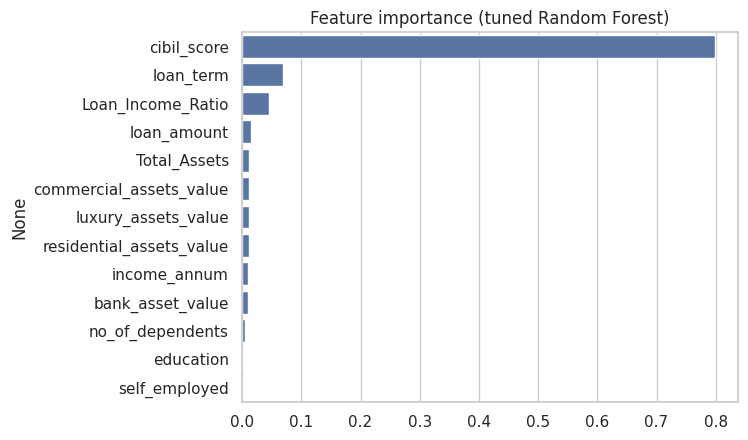

,0
cibil_score,0.798
loan_term,0.070
Loan_Income_Ratio,0.045
loan_amount,0.014
Total_Assets,0.012
commercial_assets_value,0.011
luxury_assets_value,0.011
residential_assets_value,0.011
income_annum,0.010
bank_asset_value,0.010


In [21]:
importance = pd.Series(tuned_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
sns.barplot(x=importance.values, y=importance.index)
plt.title('Feature importance (tuned Random Forest)')
plt.show()
importance.round(3)

**What the model is telling us:**
- **`cibil_score` dominates** (~0.80 importance) — consistent with the 10.6% vs 99% approval cliff from EDA.
- **`loan_term`** is second, and our engineered **`Loan_Income_Ratio`** is third — repayment burden matters more than raw income.
- **Insight → Decision for HDFC:** credit score is effectively the gatekeeper. Applicants just below ~550 are almost always rejected — HDFC could offer these borderline applicants credit-building guidance or secured-loan alternatives instead of a flat rejection.

## Step 10 — Conclusion + Limitations
**Sections 09 & 10.**

**Conclusion:** A (tuned) Random Forest predicts loan approval with ~99.5% accuracy, F1 ≈ 0.996 and ROC-AUC ≈ 1.0, and beats a 62% majority-class baseline by a wide margin. The decision is driven overwhelmingly by CIBIL score, with loan term and our engineered loan-to-income ratio as secondary factors. 5-fold cross-validation confirms the result is stable.

**Limitations (be ready to say these out loud):**
- The dataset is **synthetic** and **CIBIL-dominated**, so the near-perfect accuracy reflects the data, not real-world difficulty. On real applicant data the score would be lower.
- Few behavioural features; no repayment-history or macro-economic context.
- The model mirrors the existing approval policy — if that policy is biased, the model learns the bias.

**Improvements:**
- Validate on a real, noisier dataset for an honest accuracy estimate.
- Add a gradient-boosting model (e.g. XGBoost) to the comparison.
- Fairness check across demographic groups before any deployment.

**Deliverable made outside this notebook:** the flow diagram (Problem → Data → Preprocess → EDA → Features → Model → Evaluate → Interpret → Conclude).

## Step 11 — Live prediction on a new applicant
Turns the analysis into a usable tool: enter one applicant's details → the tuned model returns **Approved / Rejected** with a confidence score. This is our presentation demo.

In [22]:
final_model = tuned_rf   # the tuned Random Forest, our best model

def predict_loan(applicant):
    """Takes one applicant (dict of raw values) and returns the model's decision."""
    row = pd.DataFrame([applicant])
    row['education']     = row['education'].map({'Graduate': 1, 'Not Graduate': 0})
    row['self_employed'] = row['self_employed'].map({'Yes': 1, 'No': 0})

    # same engineered features as training
    row['Loan_Income_Ratio'] = row['loan_amount'] / row['income_annum']
    row['Total_Assets'] = (row['residential_assets_value'] + row['commercial_assets_value']
                           + row['luxury_assets_value'] + row['bank_asset_value'])

    # line columns up exactly like training, then scale with the SAME scaler
    row = row.reindex(columns=X.columns, fill_value=0)
    row_scaled = scaler.transform(row)

    pred = final_model.predict(row_scaled)[0]
    prob = float(final_model.predict_proba(row_scaled)[0][1]) * 100
    return ('APPROVED' if pred == 1 else 'REJECTED', round(prob, 1))

In [23]:
# Demo on two example applicants
strong_applicant = {
    'no_of_dependents': 1, 'education': 'Graduate', 'self_employed': 'No',
    'income_annum': 8000000, 'loan_amount': 20000000, 'loan_term': 12, 'cibil_score': 780,
    'residential_assets_value': 5000000, 'commercial_assets_value': 3000000,
    'luxury_assets_value': 10000000, 'bank_asset_value': 4000000}

weak_applicant = {
    'no_of_dependents': 3, 'education': 'Not Graduate', 'self_employed': 'Yes',
    'income_annum': 2000000, 'loan_amount': 15000000, 'loan_term': 10, 'cibil_score': 420,
    'residential_assets_value': 500000, 'commercial_assets_value': 0,
    'luxury_assets_value': 800000, 'bank_asset_value': 300000}

d1, p1 = predict_loan(strong_applicant)
d2, p2 = predict_loan(weak_applicant)
print(f"Strong applicant (CIBIL 780) -> {d1}  (approval probability: {p1}%)")
print(f"Weak applicant   (CIBIL 420) -> {d2}  (approval probability: {p2}%)")

Strong applicant (CIBIL 780) -> APPROVED  (approval probability: 98.0%)
Weak applicant   (CIBIL 420) -> REJECTED  (approval probability: 16.0%)


### Optional: type an applicant live (great for the viva)
Run the cell below **only when you want to enter values by hand** — it waits for your typing. Skip it during *Run all*.

In [24]:
applicant = {
    'no_of_dependents' : int(input('Number of dependents: ')),
    'education'        : input('Education (Graduate/Not Graduate): '),
    'self_employed'    : input('Self Employed (Yes/No): '),
    'income_annum'     : float(input('Annual income: ')),
    'loan_amount'      : float(input('Loan amount: ')),
    'loan_term'        : float(input('Loan term (years): ')),
    'cibil_score'      : float(input('CIBIL score (300-900): ')),
    'residential_assets_value' : float(input('Residential assets value: ')),
    'commercial_assets_value'  : float(input('Commercial assets value: ')),
    'luxury_assets_value'      : float(input('Luxury assets value: ')),
    'bank_asset_value'         : float(input('Bank asset value: ')),
}
decision, prob = predict_loan(applicant)
print(f"\nDECISION: {decision}   (approval probability: {prob}%)")

Number of dependents: 2
Education (Graduate/Not Graduate): Graduate
Self Employed (Yes/No): No
Annual income: 1000000
Loan amount: 2000000
Loan term (years): 7
CIBIL score (300-900): 650
Residential assets value: 5000000
Commercial assets value: 0
Luxury assets value: 100000
Bank asset value: 200000

DECISION: APPROVED   (approval probability: 88.5%)
